In [1]:
1

1

In [2]:
import anndata as ad
import os
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
ROOT_PATH = 'data_full_coverage'

## Download results

In [4]:
def dict_to_pd(d):
    rows = []

    for outer_key, inner in d.items():
        row = {
            "dataset_id": inner["dataset_id"],
            "method_id": inner["method_id"],
        }
        
        # Use values from "d" as column names
        for col_name, value in zip(inner["metric_ids"], inner["metric_values"]):
            row[col_name] = value
            
        rows.append(row)
    
    df = pd.DataFrame(rows, index=d.keys())
    return df

In [5]:
methods_path = f'../{ROOT_PATH}/benchmark/results/metrics/methods/'

In [6]:
file_name_err = 'mean_rowwise_error.h5ad'
file_name_corr = 'mean_rowwise_correlation.h5ad'

In [7]:
methods_err = {}
methods_corr = {}
for item in os.listdir(methods_path):
    if 'mol_emb_learning' in item:
        if 'nn_retraining_with_pseudolabels_mol_emb_subsample_fp' in item:
            name = item.replace('_all_1', '')
        else:
            name = item
        name = name.replace('nn_retraining_with_pseudolabels_mol_emb_learning_missed_subsample_', '')
        stability_path = methods_path + item + '/stability'
        for seed in os.listdir(stability_path):
            
            err = ad.read_h5ad(f'{stability_path}/{seed}/{file_name_err}').uns
            corr = ad.read_h5ad(f'{stability_path}/{seed}/{file_name_corr}').uns
            methods_err[name + '_' + seed] = err
            methods_corr[name + '_' + seed] = corr

In [8]:
df_method_err = dict_to_pd(methods_err)

In [9]:
df_method_corr = dict_to_pd(methods_corr)

In [10]:
df_method_err['method_name'] = df_method_err.index.str.split('_seed_').str[0]
df_method_err['seed'] = df_method_err.index.str.split('_seed_').str[1].astype(int)

In [11]:
df_method_corr['method_name'] = df_method_corr.index.str.split('_seed_').str[0]
df_method_corr['seed'] = df_method_corr.index.str.split('_seed_').str[1].astype(int)

In [12]:
len(df_method_corr['method_name'].unique())

31

## Mean rowwise error

### Methods

In [13]:
df_method_err.sort_values(by="mean_rowwise_rmse")

,dataset_id,method_id,mean_rowwise_rmse,mean_rowwise_mae,method_name,seed
lpm_trainable_all_20_full_cov_abl_dose_time_seed_3,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.798714,0.563078,lpm_trainable_all_20_full_cov_abl_dose_time,3
lpm_trainable_all_20_full_cov_abl_dose_time_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.798965,0.564254,lpm_trainable_all_20_full_cov_abl_dose_time,1
lpm_trainable_all_20_full_cov_abl_dose_time_seed_10,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.798994,0.563460,lpm_trainable_all_20_full_cov_abl_dose_time,10
lpm_trainable_all_20_full_cov_abl_dose_time_seed_0,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.799104,0.564924,lpm_trainable_all_20_full_cov_abl_dose_time,0
lpm_trainable_all_20_full_cov_abl_dose_time_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.799282,0.563252,lpm_trainable_all_20_full_cov_abl_dose_time,13
...,...,...,...,...,...,...
chemb1_fixed_chemb1_seed_3,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.873969,0.625402,chemb1_fixed_chemb1,3
chemb1_fixed_chemb1_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.874821,0.626358,chemb1_fixed_chemb1,1
chemb1_fixed_chemb1_seed_12,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.875506,0.626857,chemb1_fixed_chemb1,12
chemb1_fixed_chemb1_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.876100,0.627740,chemb1_fixed_chemb1,13


In [14]:
df_method_err

,dataset_id,method_id,mean_rowwise_rmse,mean_rowwise_mae,method_name,seed
lpm_fixed_l1000_last_stepmatched_seed_14,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.836196,0.594032,lpm_fixed_l1000_last_stepmatched,14
lpm_fixed_l1000_last_stepmatched_seed_4,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.836148,0.594112,lpm_fixed_l1000_last_stepmatched,4
lpm_fixed_l1000_last_stepmatched_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.837604,0.595146,lpm_fixed_l1000_last_stepmatched,13
lpm_fixed_l1000_last_stepmatched_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.838973,0.596808,lpm_fixed_l1000_last_stepmatched,1
lpm_fixed_l1000_last_stepmatched_seed_12,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.836205,0.594243,lpm_fixed_l1000_last_stepmatched,12
...,...,...,...,...,...,...
lpm_trainable_all_20_full_cov_abl_dataset_seed_10,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.804655,0.568295,lpm_trainable_all_20_full_cov_abl_dataset,10
lpm_trainable_all_20_full_cov_abl_dataset_seed_0,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.804529,0.569926,lpm_trainable_all_20_full_cov_abl_dataset,0
lpm_trainable_all_20_full_cov_abl_dataset_seed_3,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.804201,0.568408,lpm_trainable_all_20_full_cov_abl_dataset,3
lpm_trainable_all_20_full_cov_abl_dataset_seed_11,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.804223,0.567856,lpm_trainable_all_20_full_cov_abl_dataset,11


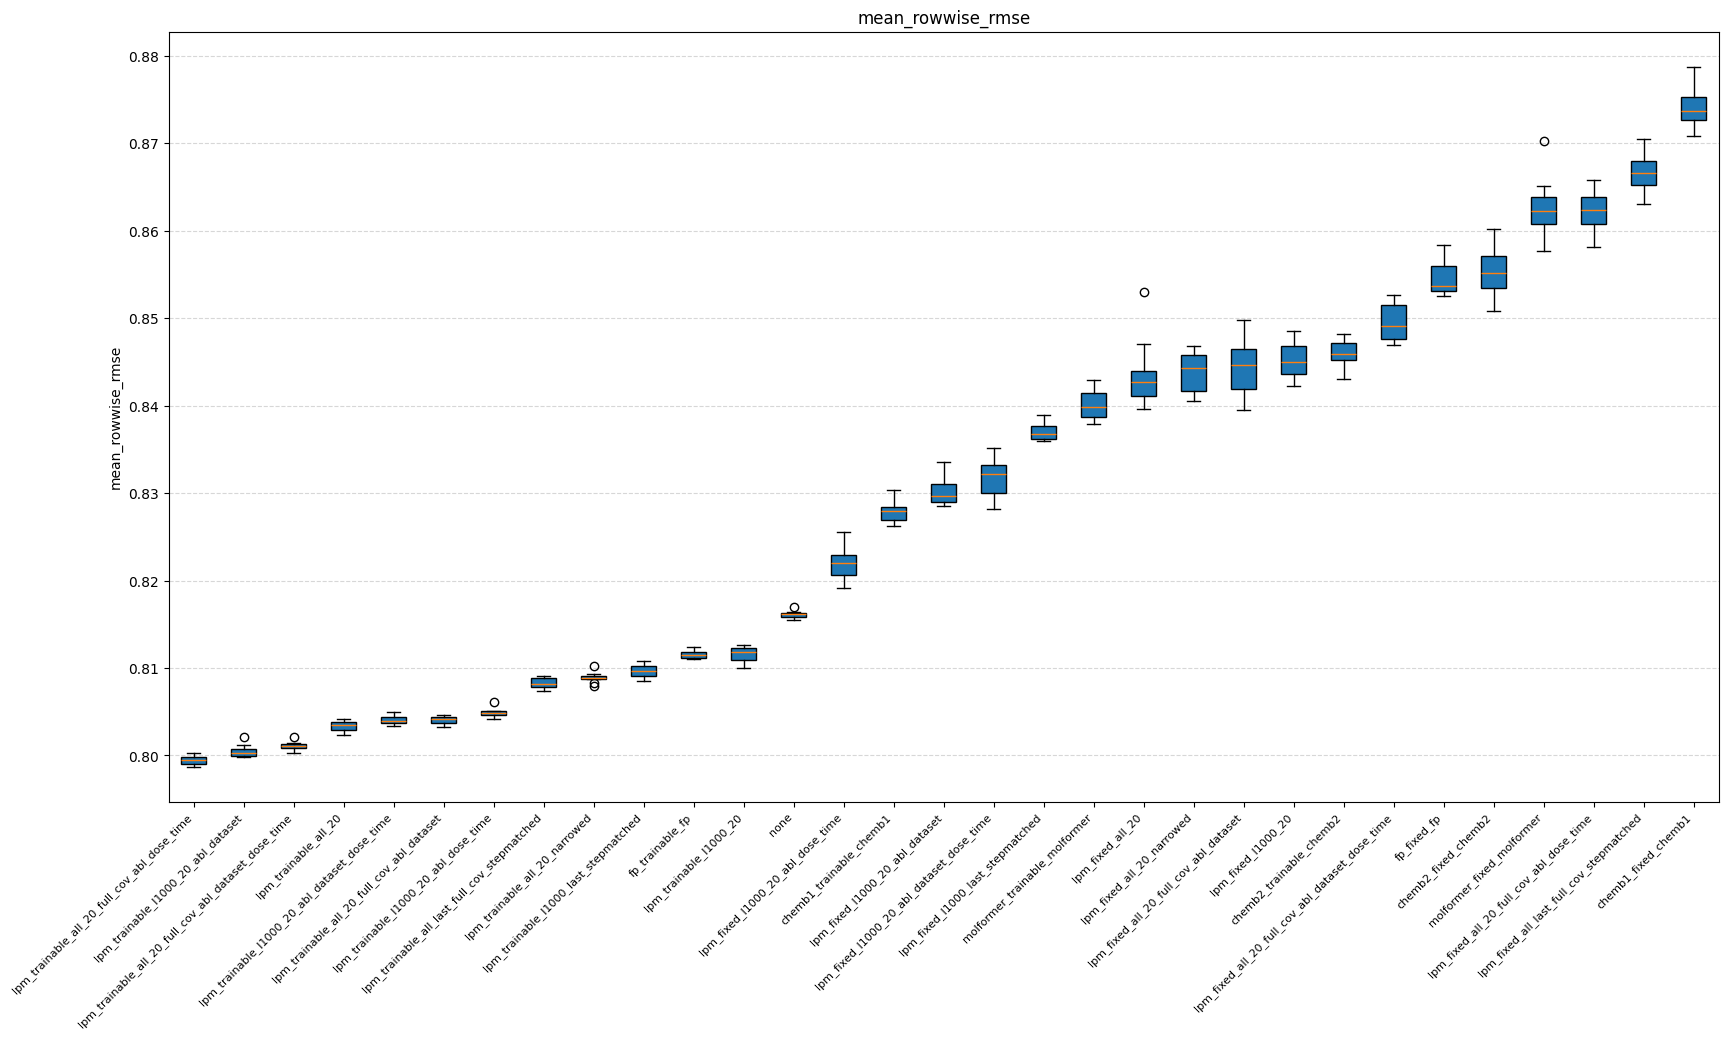

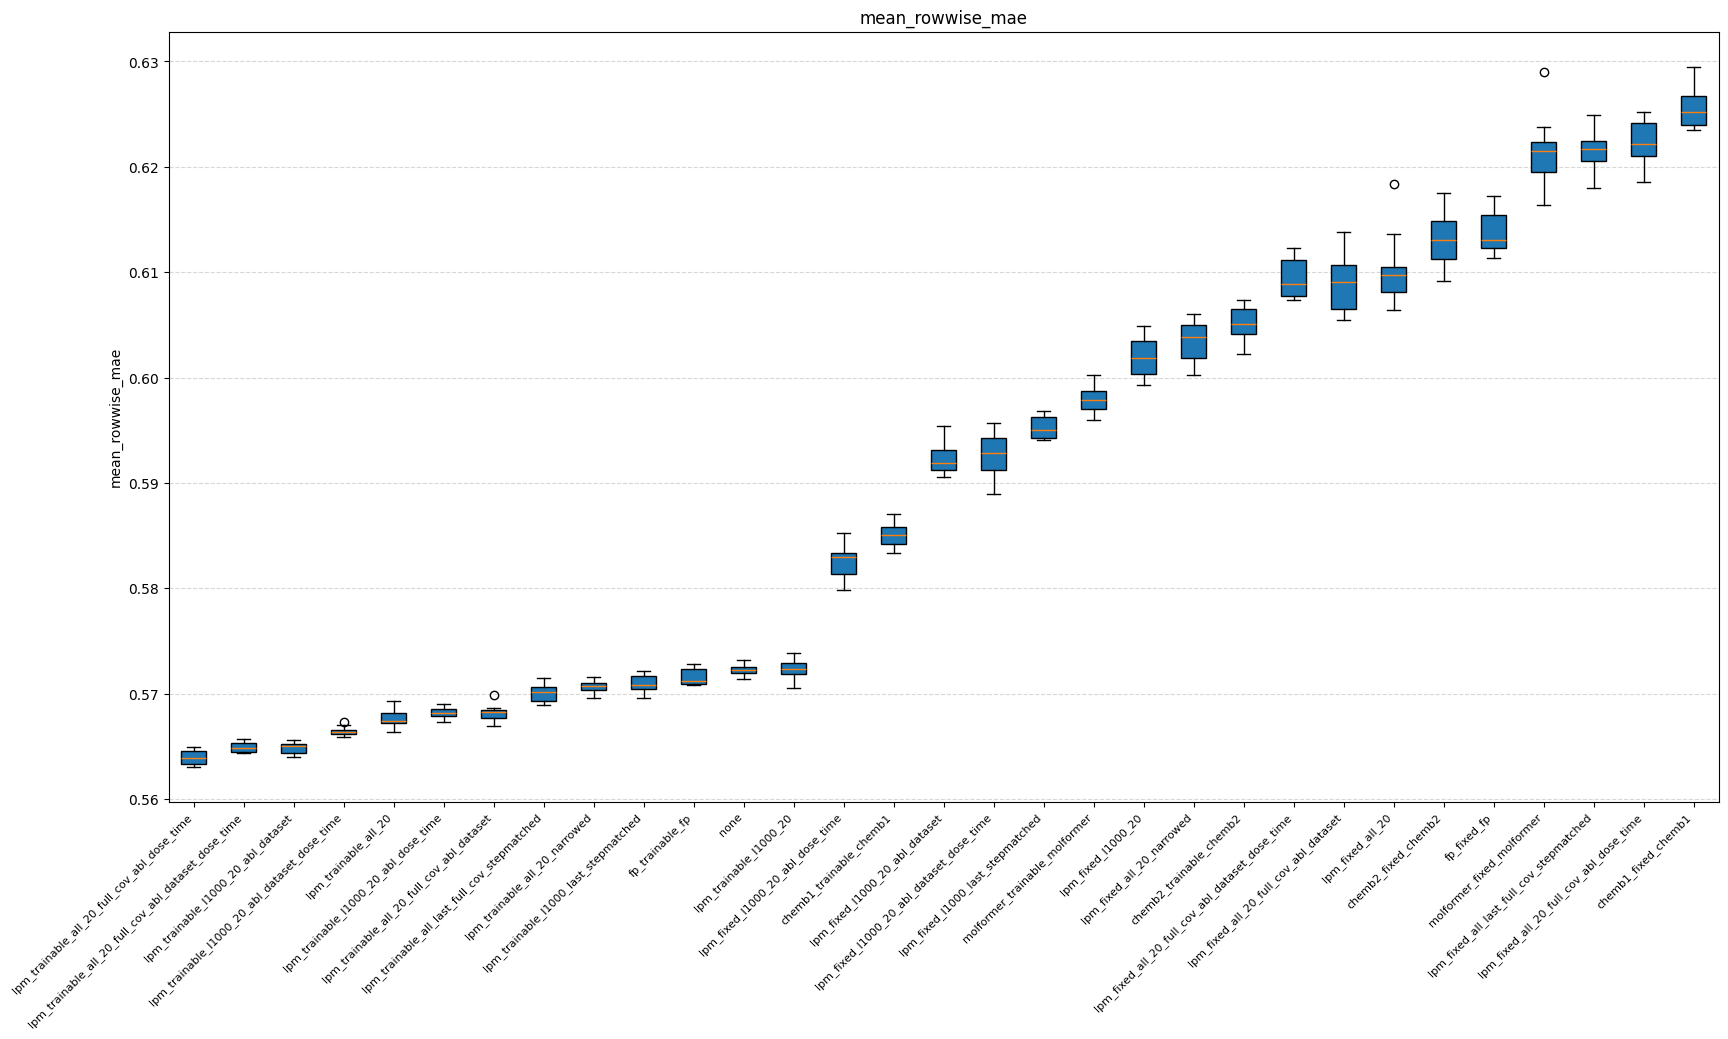

In [15]:
metrics = ["mean_rowwise_rmse", "mean_rowwise_mae"]
#fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 5))
for metric in metrics:
    # collect values per method, ordered by median
    methods_ordered = (
        df_method_err.groupby("method_name")[metric]
        .median()
        .sort_values()
        .index.tolist()
    )
    data_per_method = [
        df_method_err.loc[df_method_err["method_name"] == m, metric].values
        for m in methods_ordered
    ]
    plt.figure(figsize=(20, 10))
    plt.boxplot(data_per_method, patch_artist=True, vert=True)
    plt.xticks(
        range(1, len(methods_ordered) + 1),
        # strip the long common prefix for readability
        [m.replace("nn_retraining_with_pseudolabels_mol_emb_subsample_", "") for m in methods_ordered],
        rotation=45, ha="right", fontsize=8,
    )
    plt.ylabel(metric)
    plt.title(metric)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.show()
#fig.suptitle("Stability across seeds", fontsize=13, y=1.02)
#plt.tight_layout()


## Mean rowwise correlation

### Methods

In [16]:
df_method_corr.sort_values(by="mean_rowwise_pearson", ascending=False)
#df_method_corr.sort_values(by="mean_rowwise_spearman", ascending=False)

,dataset_id,method_id,mean_rowwise_pearson,mean_rowwise_spearman,mean_rowwise_cosine,method_name,seed
lpm_trainable_all_20_full_cov_abl_dataset_dose_time_seed_0,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.297467,0.283329,0.301254,lpm_trainable_all_20_full_cov_abl_dataset_dose...,0
lpm_trainable_all_20_full_cov_abl_dataset_dose_time_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.296209,0.281801,0.300041,lpm_trainable_all_20_full_cov_abl_dataset_dose...,1
lpm_trainable_all_20_full_cov_abl_dataset_dose_time_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.295633,0.281490,0.299494,lpm_trainable_all_20_full_cov_abl_dataset_dose...,13
lpm_trainable_all_20_full_cov_abl_dataset_dose_time_seed_14,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.295455,0.281461,0.299337,lpm_trainable_all_20_full_cov_abl_dataset_dose...,14
lpm_trainable_all_20_full_cov_abl_dataset_dose_time_seed_2,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.295025,0.281561,0.298906,lpm_trainable_all_20_full_cov_abl_dataset_dose...,2
...,...,...,...,...,...,...,...
chemb1_fixed_chemb1_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.189731,0.180826,0.194043,chemb1_fixed_chemb1,13
chemb1_fixed_chemb1_seed_10,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.188963,0.180021,0.193367,chemb1_fixed_chemb1,10
chemb1_fixed_chemb1_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.187227,0.178268,0.191561,chemb1_fixed_chemb1,1
chemb1_fixed_chemb1_seed_4,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.186872,0.177662,0.191251,chemb1_fixed_chemb1,4


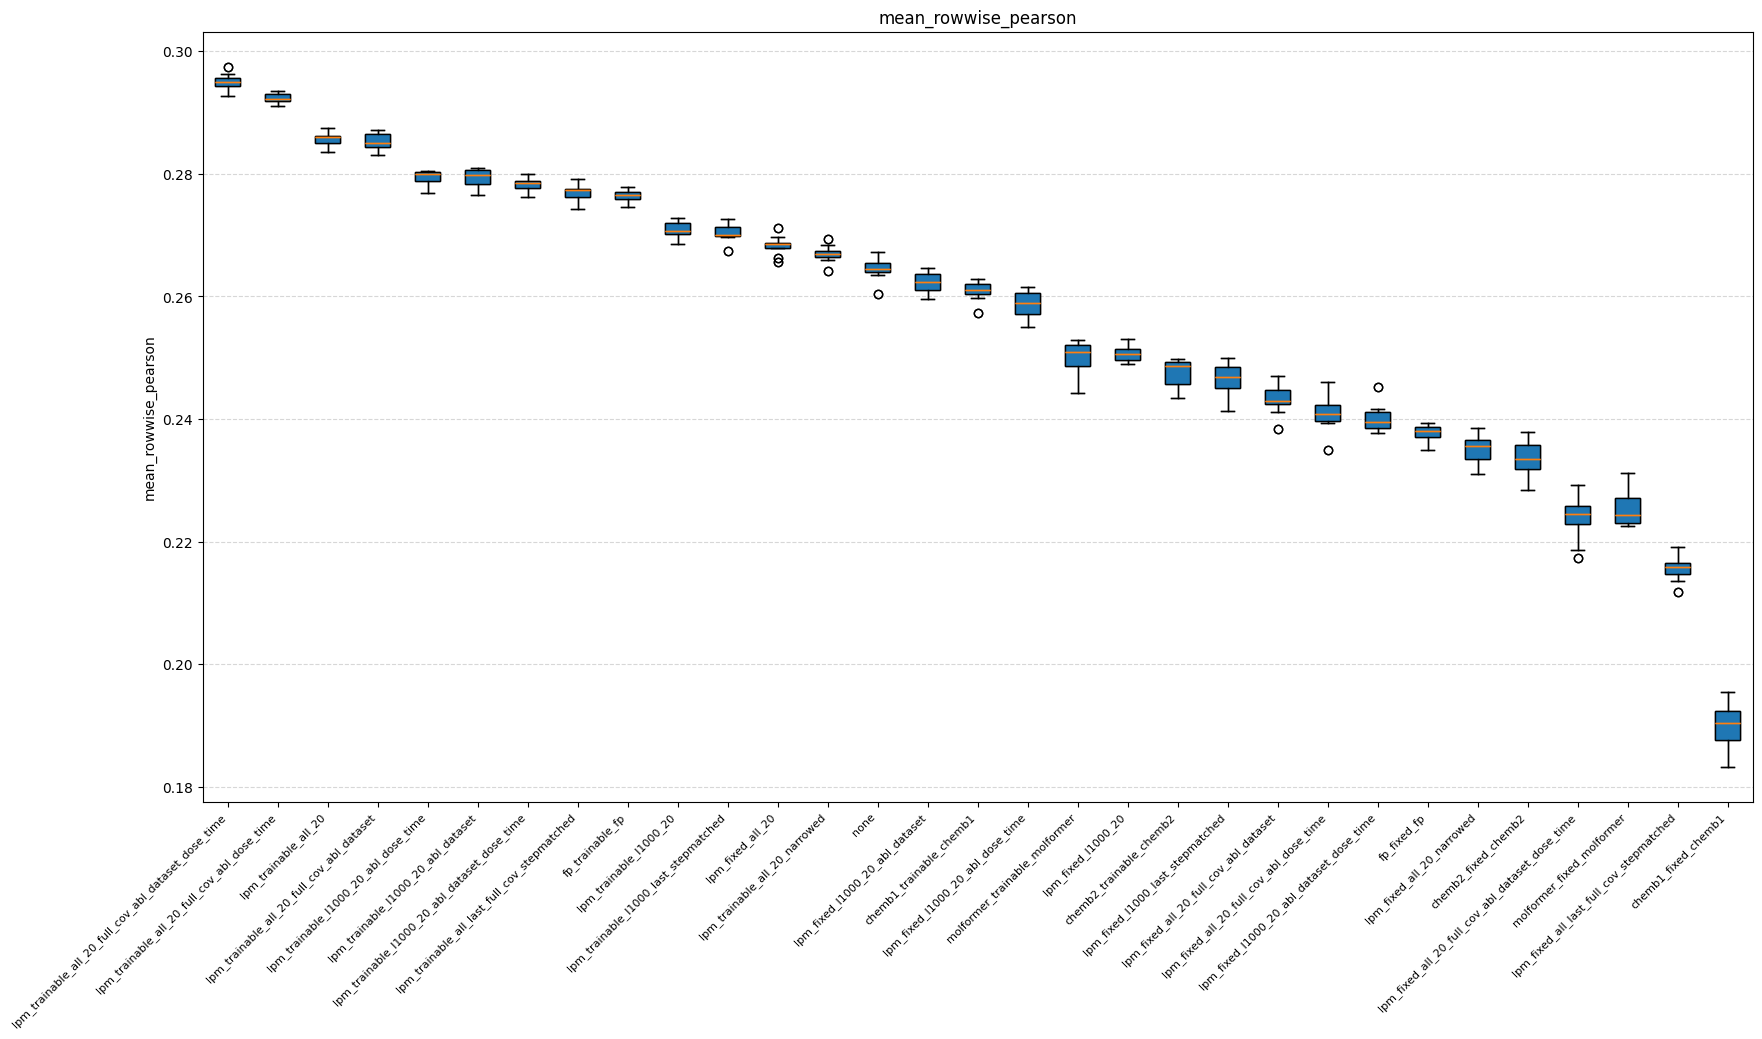

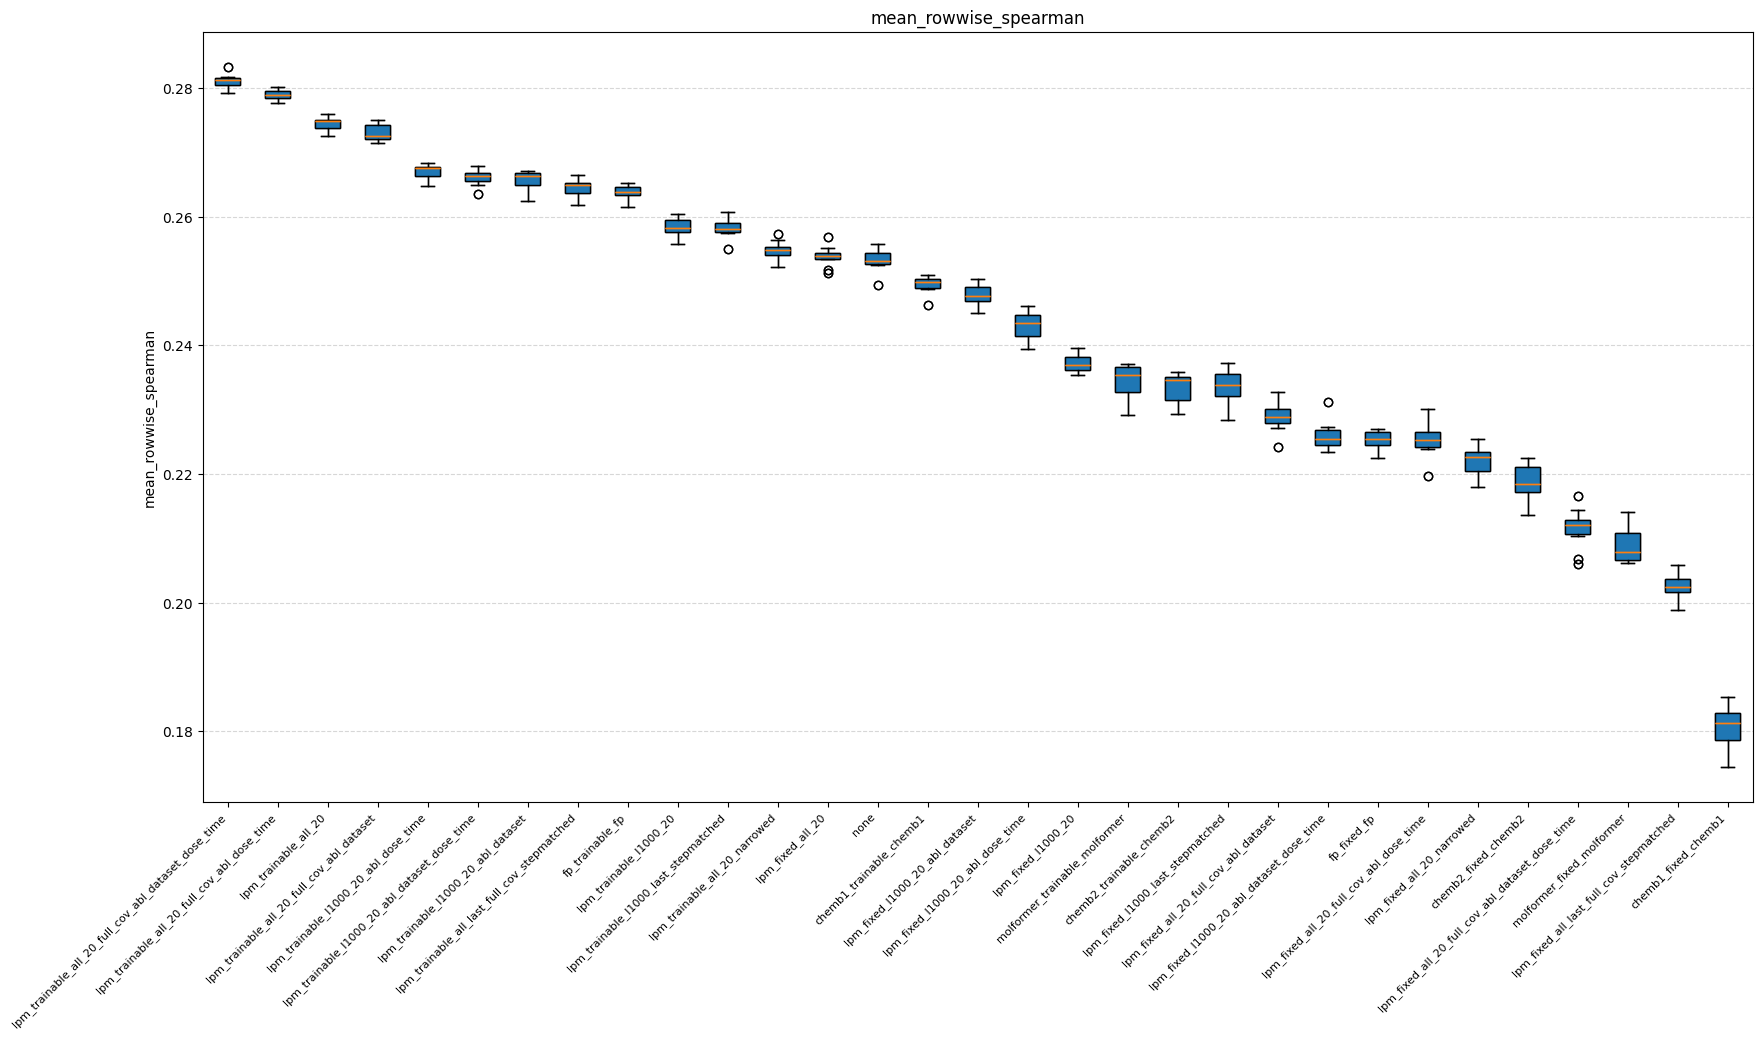

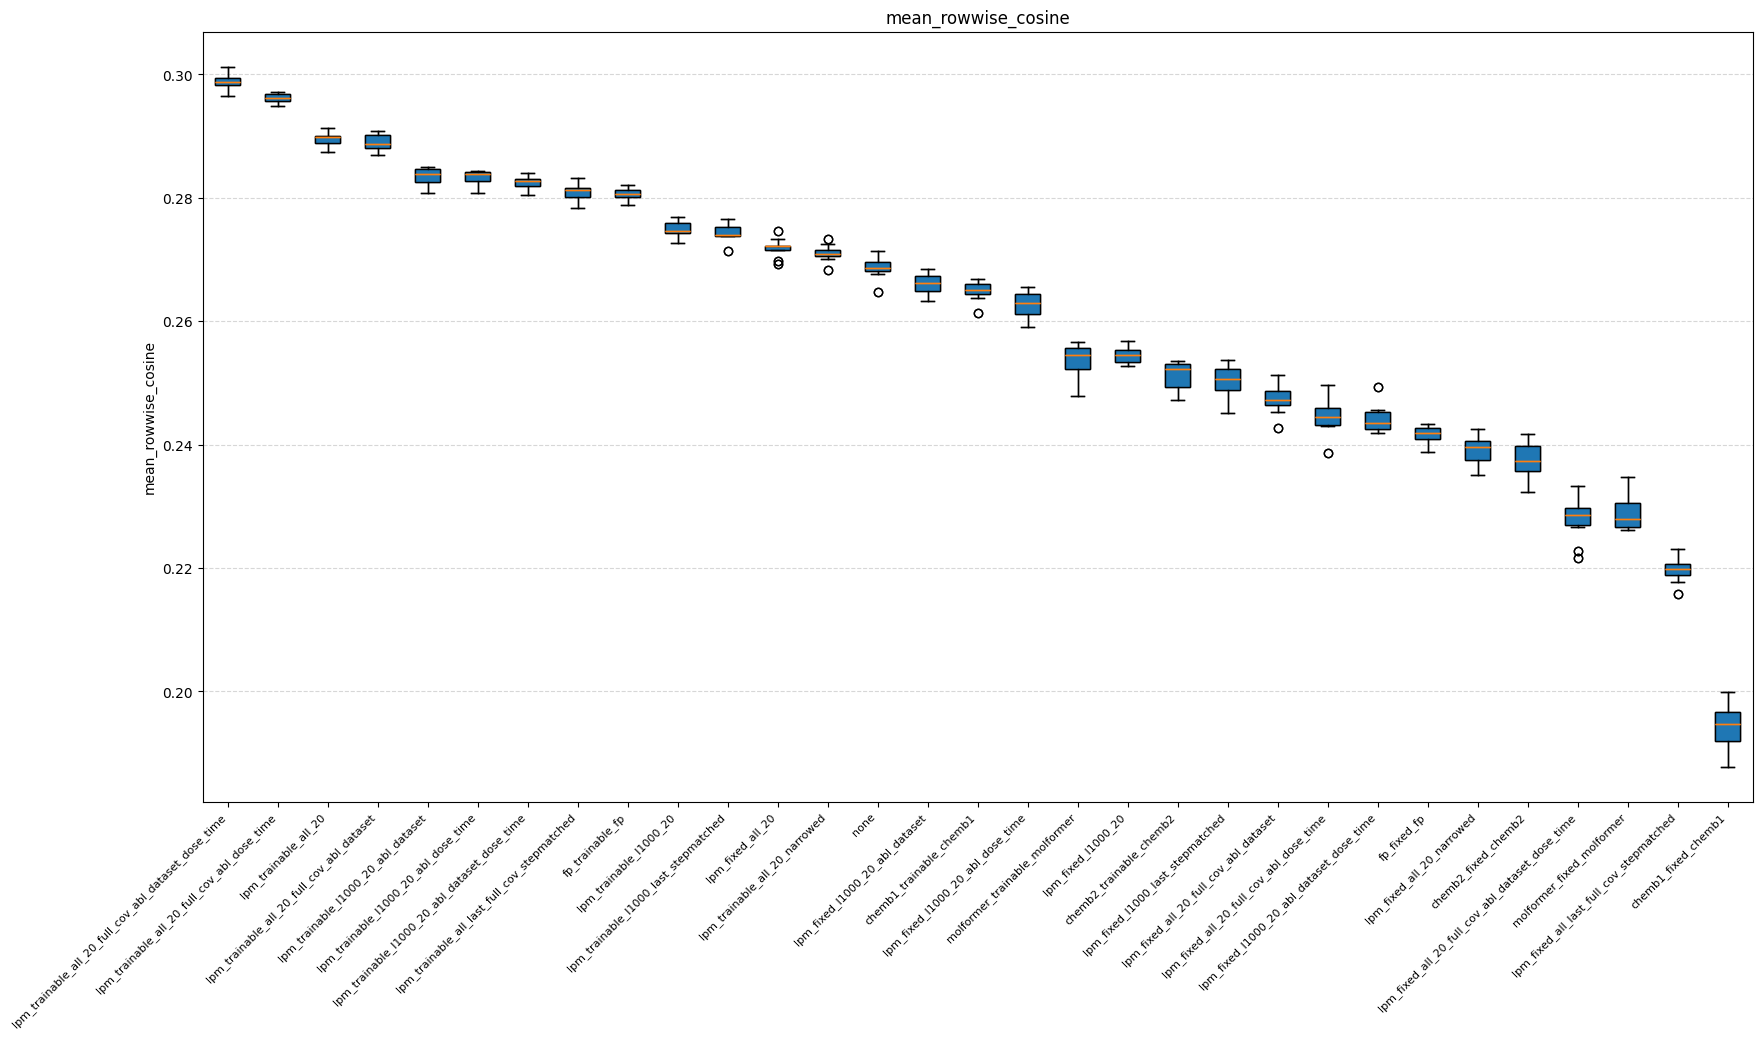

In [17]:
corr_metrics = ["mean_rowwise_pearson", "mean_rowwise_spearman", "mean_rowwise_cosine"]
for metric in corr_metrics:
    # higher correlation is better → sort descending
    methods_ordered = (
        df_method_corr.groupby("method_name")[metric]
        .median()
        .sort_values(ascending=False)
        .index.tolist()
    )
    data_per_method = [
        df_method_corr.loc[df_method_corr["method_name"] == m, metric].values
        for m in methods_ordered
    ]
    plt.figure(figsize=(20, 10))
    plt.boxplot(data_per_method, patch_artist=True, vert=True)
    plt.boxplot(data_per_method, patch_artist=True, vert=True)

    plt.xticks(
        range(1, len(methods_ordered) + 1),
        [m.replace("nn_retraining_with_pseudolabels_mol_emb_subsample_", "") for m in methods_ordered],
        rotation=45, ha="right", fontsize=8,
    )
    plt.ylabel(metric)
    plt.title(metric)
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    plt.show()

In [22]:
df_method_err

,dataset_id,method_id,mean_rowwise_rmse,mean_rowwise_mae,method_name,seed
lpm_fixed_l1000_last_stepmatched_seed_14,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.836196,0.594032,lpm_fixed_l1000_last_stepmatched,14
lpm_fixed_l1000_last_stepmatched_seed_4,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.836148,0.594112,lpm_fixed_l1000_last_stepmatched,4
lpm_fixed_l1000_last_stepmatched_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.837604,0.595146,lpm_fixed_l1000_last_stepmatched,13
lpm_fixed_l1000_last_stepmatched_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.838973,0.596808,lpm_fixed_l1000_last_stepmatched,1
lpm_fixed_l1000_last_stepmatched_seed_12,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_fixed,0.836205,0.594243,lpm_fixed_l1000_last_stepmatched,12
...,...,...,...,...,...,...
lpm_trainable_all_20_full_cov_abl_dataset_seed_10,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.804655,0.568295,lpm_trainable_all_20_full_cov_abl_dataset,10
lpm_trainable_all_20_full_cov_abl_dataset_seed_0,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.804529,0.569926,lpm_trainable_all_20_full_cov_abl_dataset,0
lpm_trainable_all_20_full_cov_abl_dataset_seed_3,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.804201,0.568408,lpm_trainable_all_20_full_cov_abl_dataset,3
lpm_trainable_all_20_full_cov_abl_dataset_seed_11,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.804223,0.567856,lpm_trainable_all_20_full_cov_abl_dataset,11


In [23]:
df_err_summary = (
    df_method_err
    .groupby("method_name")[metrics]
    .agg(["mean", "std"])
    .sort_values(("mean_rowwise_rmse", "mean"), ascending=True)
    .round(4)
)

display(df_err_summary)



df_corr_summary = (
    df_method_corr
    .groupby("method_name")[corr_metrics]
    .agg(["mean", "std"])
    .sort_values(("mean_rowwise_pearson", "mean"), ascending=False)
    .round(4)
)
display(df_corr_summary)

mean_rowwise_rmse          \
                                                                mean     std   
method_name                                                                    
lpm_trainable_all_20_full_cov_abl_dose_time                   0.7995  0.0006   
lpm_trainable_l1000_20_abl_dataset                            0.8005  0.0007   
lpm_trainable_all_20_full_cov_abl_dataset_dose_...            0.8011  0.0005   
lpm_trainable_all_20                                          0.8034  0.0006   
lpm_trainable_l1000_20_abl_dataset_dose_time                  0.8041  0.0005   
lpm_trainable_all_20_full_cov_abl_dataset                     0.8041  0.0005   
lpm_trainable_l1000_20_abl_dose_time                          0.8049  0.0005   
lpm_trainable_all_last_full_cov_stepmatched                   0.8083  0.0006   
lpm_trainable_all_20_narrowed                                 0.8089  0.0006   
lpm_trainable_l1000_last_stepmatched                          0.8097  0.0007   
fp_trainable_fp                                               0.8115  0.0004   
lpm_trainable_l1000_20                                        0.8115  0.0010   
none                                                          0.8161  0.0004   
lpm_fixed_l1000_20_abl_dose_time                              0.8219  0.0019   
chemb1_trainable_chemb1                                       0.8279  0.0012   
lpm_fixed_l1000_20_abl_dataset                                0.8302  0.0016   
lpm_fixed_l1000_20_abl_dataset_dose_time                      0.8317  0.0024   
lpm_fixed_l1000_last_stepmatched                              0.8371  0.0011   
molformer_trainable_molformer                                 0.8402  0.0018   
lpm_fixed_all_20                                              0.8435  0.0040   
lpm_fixed_all_20_narrowed                                     0.8439  0.0023   
lpm_fixed_all_20_full_cov_abl_dataset                         0.8443  0.0032   
lpm_fixed_l1000_20                                            0.8452  0.0020   
chemb2_trainable_chemb2                                       0.8460  0.0015   
lpm_fixed_all_20_full_cov_abl_dataset_dose_time               0.8496  0.0023   
fp_fixed_fp                                                   0.8547  0.0021   
chemb2_fixed_chemb2                                           0.8553  0.0028   
lpm_fixed_all_20_full_cov_abl_dose_time                       0.8621  0.0026   
molformer_fixed_molformer                                     0.8627  0.0034   
lpm_fixed_all_last_full_cov_stepmatched                       0.8665  0.0024   
chemb1_fixed_chemb1                                           0.8741  0.0023   

                                                   mean_rowwise_mae          
                                                               mean     std  
method_name                                                                  
lpm_trainable_all_20_full_cov_abl_dose_time                  0.5639  0.0007  
lpm_trainable_l1000_20_abl_dataset                           0.5648  0.0006  
lpm_trainable_all_20_full_cov_abl_dataset_dose_...           0.5649  0.0005  
lpm_trainable_all_20                                         0.5676  0.0009  
lpm_trainable_l1000_20_abl_dataset_dose_time                 0.5665  0.0005  
lpm_trainable_all_20_full_cov_abl_dataset                    0.5682  0.0008  
lpm_trainable_l1000_20_abl_dose_time                         0.5682  0.0006  
lpm_trainable_all_last_full_cov_stepmatched                  0.5701  0.0009  
lpm_trainable_all_20_narrowed                                0.5707  0.0006  
lpm_trainable_l1000_last_stepmatched                         0.5710  0.0008  
fp_trainable_fp                                              0.5716  0.0008  
lpm_trainable_l1000_20                                       0.5724  0.0009  
none                                                         0.5723  0.0005  
lpm_fixed_l1000_20_abl_dose_time                             0.5826  0.0018  
chem

mean_rowwise_pearson  \
                                                                   mean   
method_name                                                               
lpm_trainable_all_20_full_cov_abl_dataset_dose_...               0.2950   
lpm_trainable_all_20_full_cov_abl_dose_time                      0.2923   
lpm_trainable_all_20                                             0.2856   
lpm_trainable_all_20_full_cov_abl_dataset                        0.2852   
lpm_trainable_l1000_20_abl_dataset                               0.2794   
lpm_trainable_l1000_20_abl_dose_time                             0.2794   
lpm_trainable_l1000_20_abl_dataset_dose_time                     0.2784   
lpm_trainable_all_last_full_cov_stepmatched                      0.2769   
fp_trainable_fp                                                  0.2764   
lpm_trainable_l1000_20                                           0.2708   
lpm_trainable_l1000_last_stepmatched                             0.2703   
lpm_fixed_all_20                                                 0.2683   
lpm_trainable_all_20_narrowed                                    0.2669   
none                                                             0.2646   
lpm_fixed_l1000_20_abl_dataset                                   0.2624   
chemb1_trainable_chemb1                                          0.2609   
lpm_fixed_l1000_20_abl_dose_time                                 0.2587   
lpm_fixed_l1000_20                                               0.2507   
molformer_trainable_molformer                                    0.2500   
chemb2_trainable_chemb2                                          0.2476   
lpm_fixed_l1000_last_stepmatched                                 0.2463   
lpm_fixed_all_20_full_cov_abl_dataset                            0.2432   
lpm_fixed_all_20_full_cov_abl_dose_time                          0.2411   
lpm_fixed_l1000_20_abl_dataset_dose_time                         0.2401   
fp_fixed_fp                                                      0.2377   
lpm_fixed_all_20_narrowed                                        0.2350   
chemb2_fixed_chemb2                                              0.2335   
molformer_fixed_molformer                                        0.2253   
lpm_fixed_all_20_full_cov_abl_dataset_dose_time                  0.2239   
lpm_fixed_all_last_full_cov_stepmatched                          0.2156   
chemb1_fixed_chemb1                                              0.1901   

                                                            \
                                                       std   
method_name                                                  
lpm_trainable_all_20_full_cov_abl_dataset_dose_...  0.0013   
lpm_trainable_all_20_full_cov_abl_dose_time         0.0008   
lpm_trainable_all_20                                0.0013   
lpm_trainable_all_20_full_cov_abl_dataset           0.0014   
lpm_trainable_l1000_20_abl_dataset                  0.0015   
lpm_trainable_l1000_20_abl_dose_time                0.0012   
lpm_trainable_l1000_20_abl_dataset_dose_time        0.0011   
lpm_trainable_all_last_full_cov_stepmatched         0.0015   
fp_trainable_fp                                     0.0011   
lpm_trainable_l1000_20                              0.0014   
lpm_trainable_l1000_last_stepmatched                0.0014   
lpm_fixed_all_20                                    0.0015   
lpm_trainable_all_20_narrowed                       0.0014   
none                                                0.0019   
lpm_fixed_l1000_20_abl_dataset                      0.0017   
chemb1_trainable_chemb1                             0.0016   
lpm_fixed_l1000_20_abl_dose_time                    0.0024   
lpm_fixed_l1000_20                                  0.0013   
molformer_trainable_molformer                       0.0030   
chemb2_trainable_chemb2                             0.0023   
lpm_fixed_l1000_last_stepmatched                    0.0028   
lpm_fixed_al

In [24]:
os.makedirs('../results', exist_ok=True)

In [25]:
df_err_summary.to_csv('../results/df_err_summary_full_coverage.csv')
df_corr_summary.to_csv('../results/df_corr_summary_full_coverage.csv')